In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

df = pd.read_csv("Titanic-Dataset.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [6]:
df.describe(include='object')

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,B96 B98,S
freq,1,577,7,4,644


In [7]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

In [8]:
print("Mean Age:", df["Age"].mean())
print("Median Age:", df["Age"].median())
print("Standard Deviation of Age:", df["Age"].std())

Mean Age: 29.69911764705882
Median Age: 28.0
Standard Deviation of Age: 14.526497332334044


In [9]:
print("Mean Fare:", df["Fare"].mean())
print("Median Fare:", df["Fare"].median())
print("Standard Deviation of Fare:", df["Fare"].std())

Mean Fare: 32.204207968574636
Median Fare: 14.4542
Standard Deviation of Fare: 49.693428597180905


In [10]:
df[['Age', 'Fare', 'SibSp', 'Parch']].describe()

,Age,Fare,SibSp,Parch
count,714.000000,891.000000,891.000000,891.000000
mean,29.699118,32.204208,0.523008,0.381594
std,14.526497,49.693429,1.102743,0.806057
min,0.420000,0.000000,0.000000,0.000000
25%,20.125000,7.910400,0.000000,0.000000
50%,28.000000,14.454200,0.000000,0.000000
75%,38.000000,31.000000,1.000000,0.000000
max,80.000000,512.329200,8.000000,6.000000


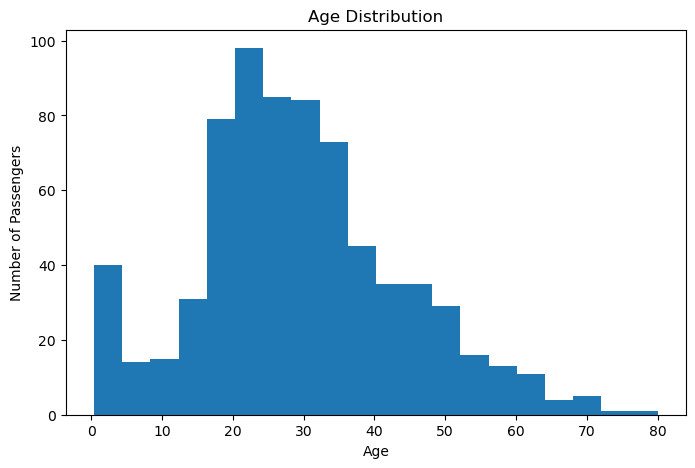

In [11]:
plt.figure(figsize=(8,5))

plt.hist(df['Age'].dropna(), bins=20)

plt.xlabel("Age")
plt.ylabel("Number of Passengers")
plt.title("Age Distribution")

plt.show()

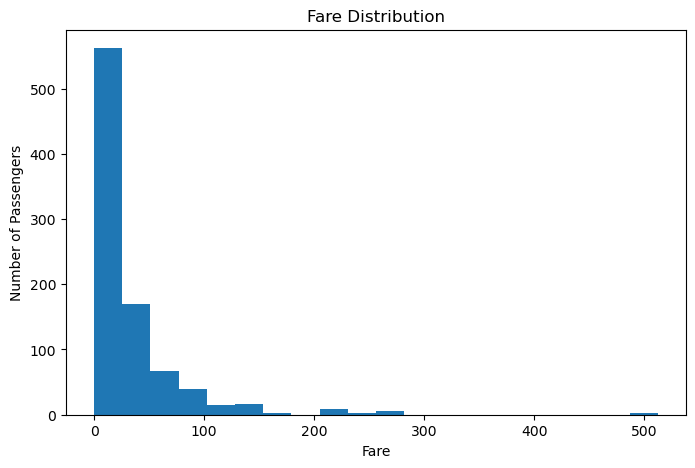

In [12]:
plt.figure(figsize=(8,5))

plt.hist(df['Fare'], bins=20)

plt.xlabel("Fare")
plt.ylabel("Number of Passengers")
plt.title("Fare Distribution")

plt.show()

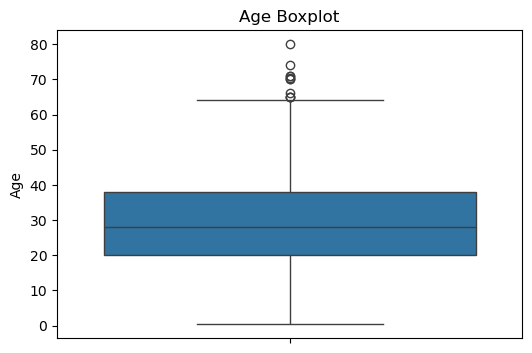

In [13]:
plt.figure(figsize=(6,4))

sns.boxplot(y=df['Age'])

plt.title("Age Boxplot")

plt.show()

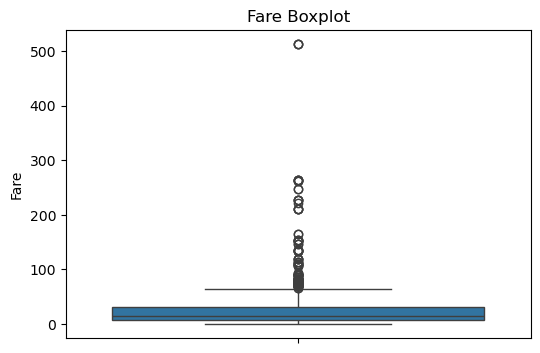

In [14]:
plt.figure(figsize=(6,4))

sns.boxplot(y=df['Fare'])

plt.title("Fare Boxplot")

plt.show()

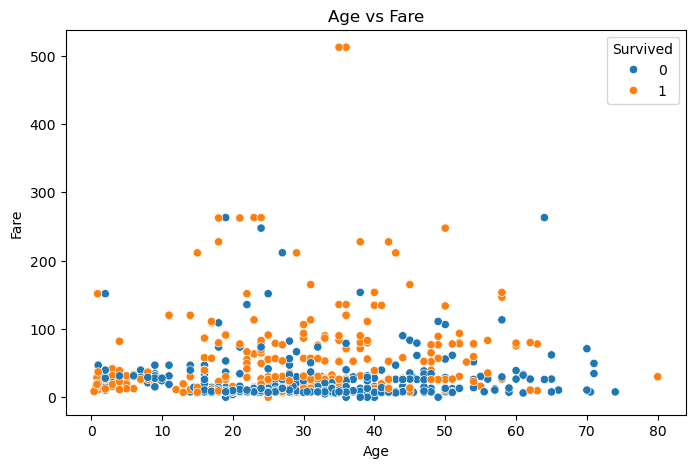

In [15]:
plt.figure(figsize=(8,5))

sns.scatterplot(data=df, x='Age', y='Fare', hue='Survived')

plt.title("Age vs Fare")
plt.show()

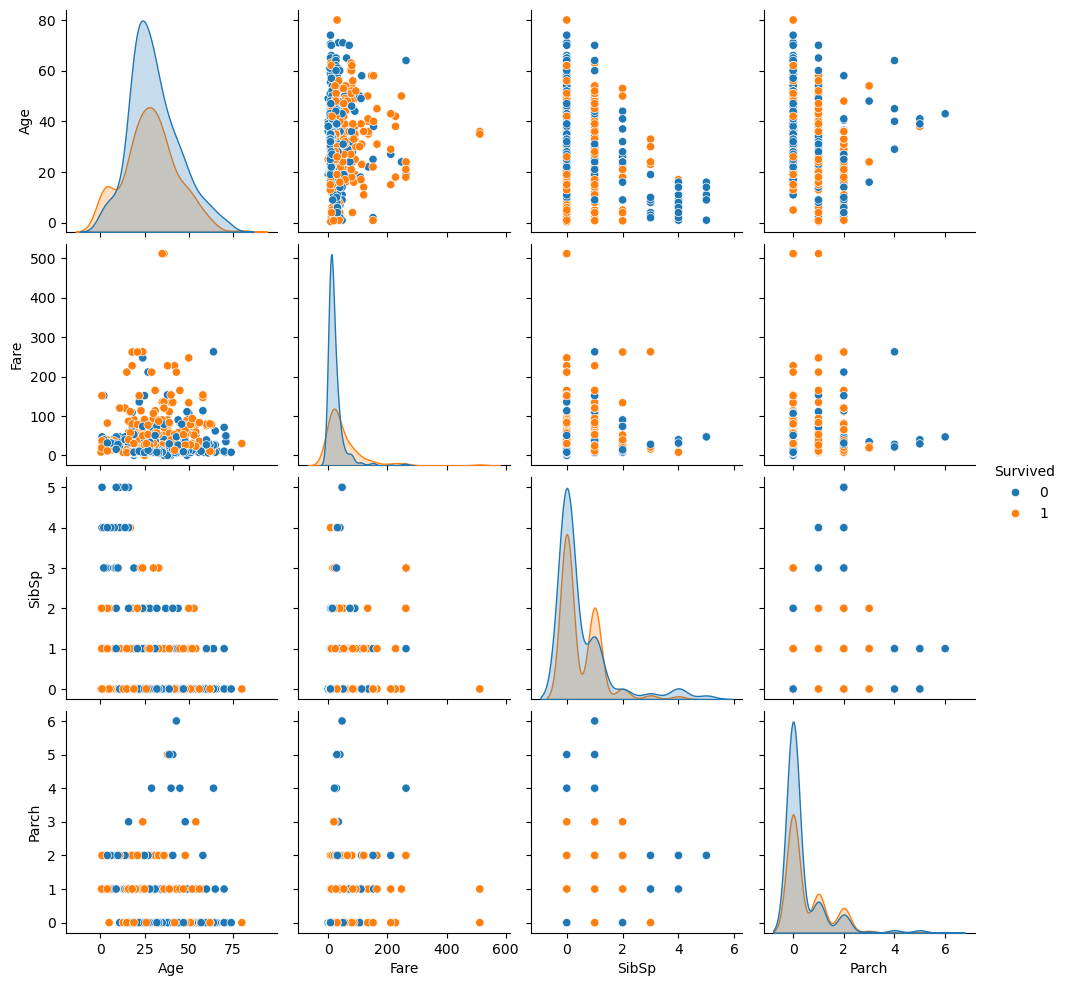

In [16]:
sns.pairplot(
    df[['Age', 'Fare', 'SibSp', 'Parch', 'Survived']].dropna(),
    hue='Survived'
)

plt.show()

In [17]:
corr = df[['Age', 'Fare', 'SibSp', 'Parch', 'Survived']].corr()

corr

,Age,Fare,SibSp,Parch,Survived
Age,1.000000,0.096067,-0.308247,-0.189119,-0.077221
Fare,0.096067,1.000000,0.159651,0.216225,0.257307
SibSp,-0.308247,0.159651,1.000000,0.414838,-0.035322
Parch,-0.189119,0.216225,0.414838,1.000000,0.081629
Survived,-0.077221,0.257307,-0.035322,0.081629,1.000000


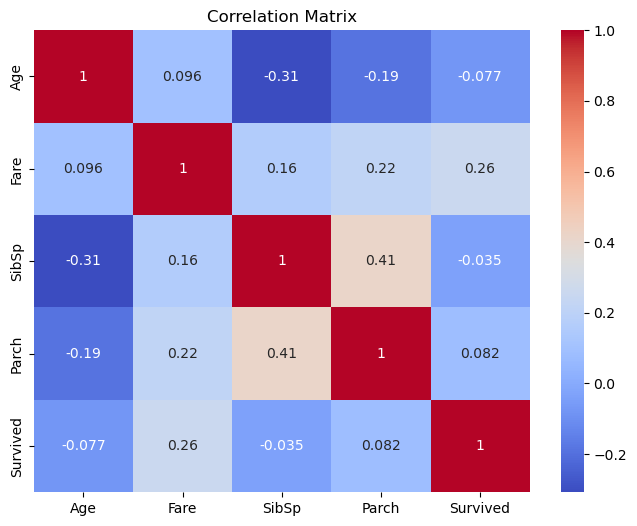

In [18]:
plt.figure(figsize=(8,6))

sns.heatmap(corr, annot=True, cmap='coolwarm')

plt.title("Correlation Matrix")

plt.show()

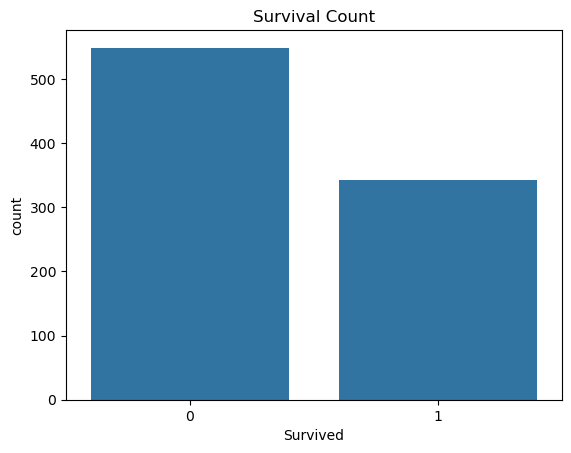

In [19]:
sns.countplot(data=df, x='Survived')

plt.title("Survival Count")
plt.show()

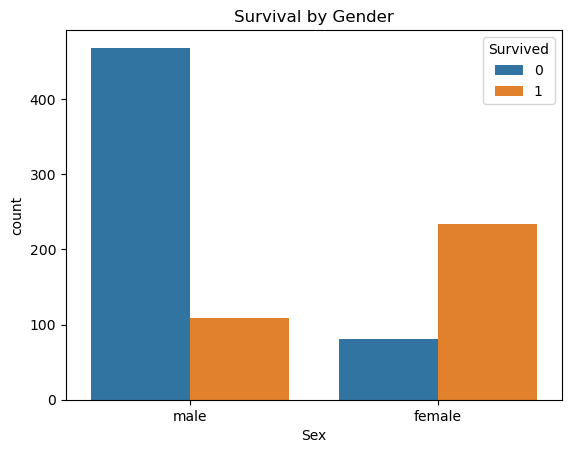

In [20]:
sns.countplot(data=df, x='Sex', hue='Survived')

plt.title("Survival by Gender")
plt.show()

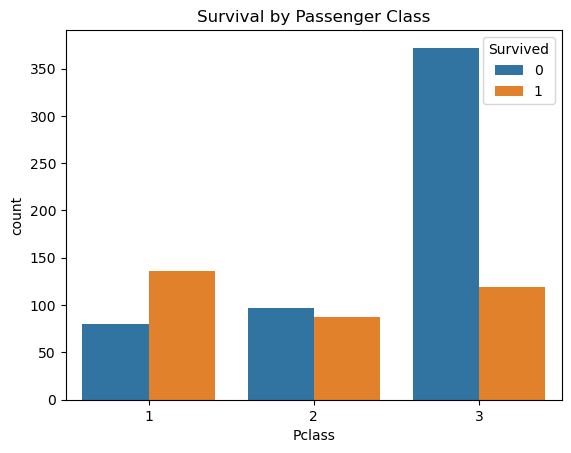

In [21]:
sns.countplot(data=df, x='Pclass', hue='Survived')

plt.title("Survival by Passenger Class")
plt.show()

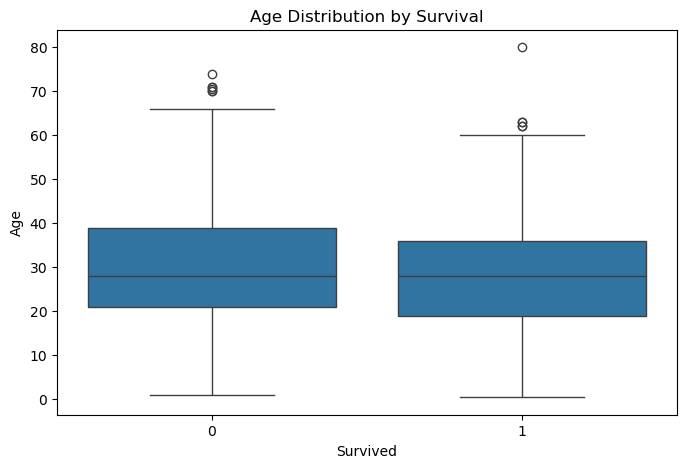

In [22]:
plt.figure(figsize=(8,5))

sns.boxplot(data=df, x='Survived', y='Age')

plt.title("Age Distribution by Survival")
plt.show()

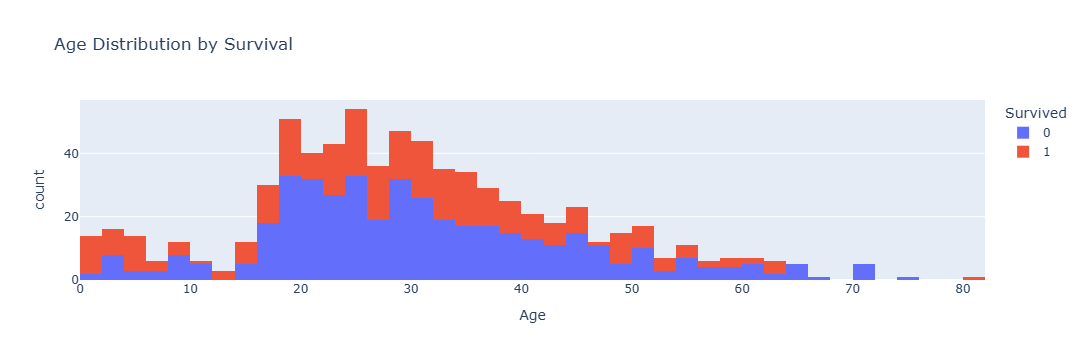

In [23]:
fig = px.histogram(
    df,
    x='Age',
    color='Survived',
    title='Age Distribution by Survival'
)

fig.show()

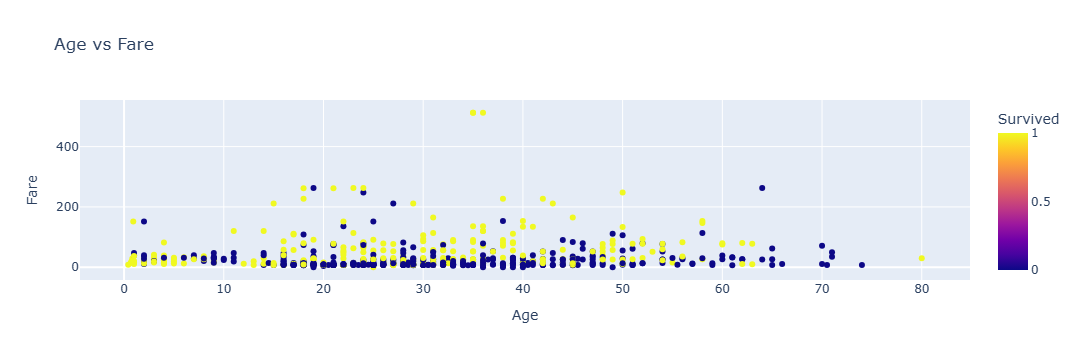

In [24]:
fig = px.scatter(
    df,
    x='Age',
    y='Fare',
    color='Survived',
    title='Age vs Fare'
)

fig.show()